# UC2 · Jalon 3 — Une nouvelle boutique, deux tâches
 **Groupe 13 · Master SDIA-2 · ENSET Mohammedia**  
 Agrigah Aya · AARAB Mustapha · Toubani Badr Eddine

 Adapter un CNN appris sur A aux 500 annonces B, comparer les modalités puis partager une représentation pour catégorie et prix.

 **Données officielles :** les quatre fichiers NPZ du dossier `Use Cases.rar`,
 partitions imposées conservées. Fashion-MNIST fournit les images ; descriptions,
 prix, boutique B et sessions sont des données pédagogiques simulées. Nous
 n'affirmons pas entraîner un système de production sur de vraies ventes.

 Le projet Kaggle antérieur reste dans `annexes/historique_kaggle`. Il ne possède
 pas les prix/sessions ni les partitions imposées. Ses scores ne sont pas mêlés
 aux résultats de cette remise. Le groupe a utilisé une assistance IA pour le
 code, la rédaction et les contrôles ; les sorties chiffrées sont calculées.

## Exécution et fichiers à conserver
 1. Décompresser **toute** l'archive, garder `data_UC2/` et `src/` avec les notebooks.
 2. Suivre le README pour l'environnement Python 3.12, TensorFlow 2.20 / Keras 3.11.3.
 3. VS Code : extensions Python/Jupyter, choisir `.venv-uc2` comme noyau. Colab :
    GPU facultatif, placer le dossier complet dans Drive puis ouvrir ce notebook.
 4. Exécuter dans l'ordre. Les modèles livrés sont réutilisés lorsqu'ils sont compatibles.
    Pour une nouvelle exécution indépendante, renseigner `RUN_LABEL` ci-dessous.
 5. Sauvegarder le notebook avec sorties. Les modèles, courbes, journal et décisions
    s'enregistrent dans `artifacts/jalonN/` (ou `reruns/RUN_LABEL/jalonN/`).

 Tous les réglages précèdent l'ouverture du test. La session finale est figée par
 empreintes des poids et de la configuration. Une relance lit les résultats
 finalisés. Ne pas modifier un modèle/seuil après accès au test pour améliorer
 artificiellement le score. Les comparateurs fixés sont évalués dans cette même
 session finale. Le temps mesuré dépend du matériel et exclut l'installation.

In [1]:
import os,sys,subprocess
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL","2")
assert (3,10)<=sys.version_info[:2]<=(3,13), "Utiliser Python 3.12."
# Configuration facultative avant exécution, pas après le test.
PROJECT_DIR = None  # Colab : "/content/drive/MyDrive/GroupeXX_UC2"
RUN_LABEL = ""      # ex. "reproduction_cpu" pour un nouveau dossier de résultats
if PROJECT_DIR:
    ROOT=Path(PROJECT_DIR).expanduser().resolve()
else:
    candidates=[Path.cwd(),Path.cwd().parent]
    ROOT=next((p for p in candidates if (p/"data_UC2/uc2_catalogueA.npz").exists()),None)
    if ROOT is None:raise FileNotFoundError("Ouvrir le dossier complet de l'archive ou définir PROJECT_DIR.")
sys.path.insert(0,str(ROOT/"src"))
from uc2_utils import *
from tensorflow.keras import layers
CFG={'source_epochs': 8, 'target_epochs': 25, 'batch': 128, 'patience': 4, 'fine_tune_lr': 0.0001, 'lambdas': [0.1, 1.0, 5.0], 'strategy_selection': 'B val accuracy', 'multitask_selection': 'B val accuracy minus .25 * MAPE', 'augmentation': 'rotation .05, translation .08, zoom .10, contrast .20, brightness .12'}
OUT,ENV,DATA_SHA=initialise(ROOT,3,CFG,RUN_LABEL)
display(pd.DataFrame([ENV]).T.rename(columns={0:"Valeur"}))
print("Dossier :",ROOT,"| résultats :",OUT)
print("GPU :",ENV["devices"] or "CPU (4 threads)")

Dossier : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2 | résultats : /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon3
GPU : CPU (4 threads)


,Valeur
python,"3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 2..."
platform,Linux-6.18.44-x86_64-with-glibc2.39
tensorflow,2.20.0
keras,3.11.3
devices,[]
cpu_threads,4
seed,42
numpy,2.3.5
pandas,2.2.3
scipy,1.17.0


## 1. Données B et préannonce des expériences
 Partitions A : 20 000/4 000/6 000. B : **500/200/2 000**, toutes conservées.
 Le vocabulaire appris sur train A est réutilisé sur B, sans ajout des mots test.
 La boutique B est une simulation de changement d'apparence, pas un jeu de
 nouvelles photographies réellement collectées au smartphone.

 CNN source : deux convolutions same 32/64, pooling, Dense128, Dropout0,3, softmax.
 Budget source 8 époques comme le départ fourni. Cinq stratégies B à 25 époques
 maximales : zéro, sortie seule, convolutions gelées, ajustement complet et
 ajustement augmenté. Changement de `trainable` **avant recompilation**. LR=1e-4
 en ajustement complet, 1e-3 pour extraction/zéro, sans modification après test.

 Contrôles de modalité : source image versus source texte sur val A/B, puis
 modèles B image seule/texte seul/fusion. Multitâche : tête catégorie softmax,
 tête log-prix linéaire, CE + λ Huber, λ=0,1/1/5. Log-prix standardisé avec **train B**.
 Contrôles à une tâche partagent la même architecture de tronc et le même budget.
 Retenir λ sur score val `accuracy − 0,25×MAPE`, convention transparente de ce
 TP et non une fonction de bénéfice économique universelle. Tester ensuite
 seulement le multitâche retenu et les comparateurs fixes, dans une seule session.

,split,rows,empty_descriptions,median_price_dh,min_price_dh,max_price_dh
0,train,20000,1043,270.0,30.0,2735.0
1,val,4000,225,265.0,35.0,2585.0


,split,rows,empty_descriptions,median_price_dh,min_price_dh,max_price_dh
0,train,500,27,272.5,40.0,1915.0
1,val,200,11,287.5,45.0,1640.0


,domain,mean_intensity,intensity_std,border_mean,border_std
0,A_train,0.285770,0.353212,0.046802,0.147564
1,B_train,0.389602,0.189514,0.279411,0.108959


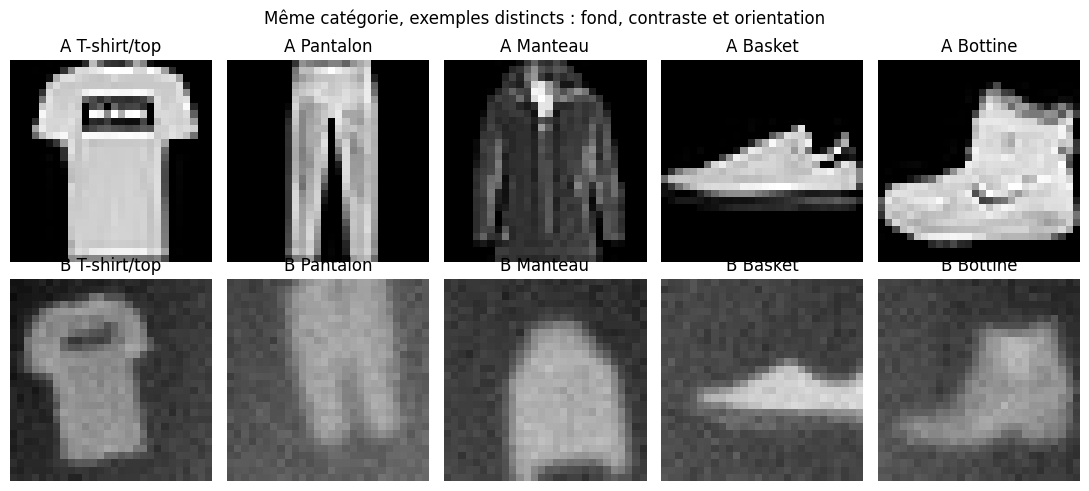

In [2]:
A=load_catalogue(ROOT,'A');B=load_catalogue(ROOT,'B');display(catalogue_audit(A));display(catalogue_audit(B))
assert len(B['X_train'])==500 and len(B['X_val'])==200
BOW=fit_bow(A);write_json(OUT/'vocabulary.json',BOW.vocabulary_)
IA={s:image_input(A,s) for s in ['train','val']};IB={s:image_input(B,s) for s in ['train','val']}
MA={s:bow_input(BOW,A,s) for s in ['train','val']};MB={s:bow_input(BOW,B,s) for s in ['train','val']}
YA={s:A['categorie_'+s] for s in ['train','val']};YB={s:B['categorie_'+s] for s in ['train','val']}
def appearance(x):
    border=np.concatenate([x[:,0,:,0],x[:,-1,:,0],x[:,:,0,0],x[:,:,-1,0]],axis=1)
    return {'mean_intensity':float(x.mean()),'intensity_std':float(x.std()),'border_mean':float(border.mean()),'border_std':float(border.std())}
SHIFT=pd.DataFrame([{'domain':'A_train',**appearance(IA['train'])},{'domain':'B_train',**appearance(IB['train'])}])
display(SHIFT);SHIFT.to_csv(OUT/'domain_shift_statistics.csv',index=False)
fig,axes=plt.subplots(2,5,figsize=(11,5))
for column,k in enumerate([0,1,4,7,9]):
    for row,(images,y,label) in enumerate([(IA['train'],YA['train'],'A'),(IB['train'],YB['train'],'B')]):
        i=np.flatnonzero(y==k)[0];axes[row,column].imshow(images[i,...,0],cmap='gray',vmin=0,vmax=1)
        axes[row,column].set_title(label+' '+CLASSES[k]);axes[row,column].axis('off')
fig.suptitle('Même catégorie, exemples distincts : fond, contraste et orientation')
fig.tight_layout();fig.savefig(OUT/'domain_shift_examples.png',dpi=150);plt.show();plt.close(fig)

## 2. Vérifications théoriques
 `L=Lcat+λLprix`, avec Lcat=0,35, Lprix=0,08.
 - λ=1 : total 0,43, part catégorie 0,35/0,43 = **81,40%**.
 - λ=5 : total 0,75, part catégorie 0,35/0,75 = **46,67%**.
 Le gradient partagé est `∇Lcat+λ∇Lprix`. Ces fractions de valeurs de perte ne
 mesurent pas directement la norme des gradients : directions et dérivées diffèrent.

 CNN source same/same : Conv1=320, Conv2=18 496, Dense128=401 536, sortie=1 290,
 total **421 642**. (a) Sortie seule : **1 290** entraînables.
 (b) Convolutions gelées, denses ajustées : **402 826**.
 (c) Ajustement complet : **421 642**. Geler les convolutions laisse donc la
 très grosse couche aplatie/dense libre ; cela n'est pas une petite tête linéaire.

In [3]:
def source_cnn():
    inp=keras.Input((28,28,1),name='image')
    x=layers.Conv2D(32,3,padding='same',activation='relu',name='conv1')(inp);x=layers.MaxPooling2D(name='pool1')(x)
    x=layers.Conv2D(64,3,padding='same',activation='relu',name='conv2')(x);x=layers.MaxPooling2D(name='pool2')(x)
    x=layers.Flatten(name='flatten')(x);x=layers.Dense(128,activation='relu',name='representation')(x)
    out=layers.Dense(10,activation='softmax',name='categorie')(layers.Dropout(.3,name='dropout')(x))
    m=keras.Model(inp,out,name='source_cnn');m.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy');return m
def source_text():
    inp=keras.Input((169,),name='mots');x=layers.Dense(128,activation='relu')(inp);x=layers.Dropout(.3)(x)
    m=keras.Model(inp,layers.Dense(10,activation='softmax')(x));m.compile(keras.optimizers.Adam(1e-3),'sparse_categorical_crossentropy');return m
SOURCE,source_info=fit_model(OUT,'CNN_A_source',source_cnn,IA['train'],YA['train'],IA['val'],YA['val'],epochs=CFG['source_epochs'],
    monitor='val_macro_f1',mode='max',evaluator=lambda p:{'val_macro_f1':classifier_metrics(YA['val'],p)['macro_f1']})
TEXT_SOURCE,text_source_info=fit_model(OUT,'BoW_A_source',source_text,MA['train'],YA['train'],MA['val'],YA['val'],epochs=CFG['source_epochs'],
    monitor='val_macro_f1',mode='max',evaluator=lambda p:{'val_macro_f1':classifier_metrics(YA['val'],p)['macro_f1']})
SOURCE_ROWS=[]
for name,model,xa,xb in [('image',SOURCE,IA['val'],IB['val']),('texte',TEXT_SOURCE,MA['val'],MB['val'])]:
    am=classifier_metrics(YA['val'],predict(model,xa));bm=classifier_metrics(YB['val'],predict(model,xb))
    SOURCE_ROWS.append({'modality':name,'A_val_accuracy':am['accuracy'],'B_val_accuracy':bm['accuracy'],
                        'drop_accuracy':am['accuracy']-bm['accuracy'],'A_val_f1':am['macro_f1'],'B_val_f1':bm['macro_f1']})
SOURCE_VAL=write_table(OUT,'source_domain_validation',SOURCE_ROWS)
SOURCE.summary();assert SOURCE.count_params()==421642

Model: "source_cnn"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼─────────────────────

,modality,A_val_accuracy,B_val_accuracy,drop_accuracy,A_val_f1,B_val_f1
0,image,0.90375,0.320,0.58375,0.904096,0.313563
1,texte,0.74750,0.655,0.09250,0.754241,0.658203


/workspace/scratch/5ba8c7023440/uc2_submission_work/.venv_uc2/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 18 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


,strategy,trainable_parameters
0,head_only,1290
1,frozen_convs,402826
2,fine_tune,421642


,model,macro_f1,accuracy,parameters,trainable_parameters,seconds,best_epoch,strategy
0,B_scratch,0.457670,0.505,421642,421642,2.939883,6,scratch
1,B_head_only,0.556492,0.555,421642,1290,3.751581,24,head_only
2,B_frozen_convs,0.662809,0.675,421642,402826,2.280281,7,frozen_convs
3,B_fine_tune,0.658489,0.665,421642,421642,5.882278,19,fine_tune
4,B_fine_tune_aug,0.658973,0.685,421642,421642,7.163656,23,fine_tune_aug


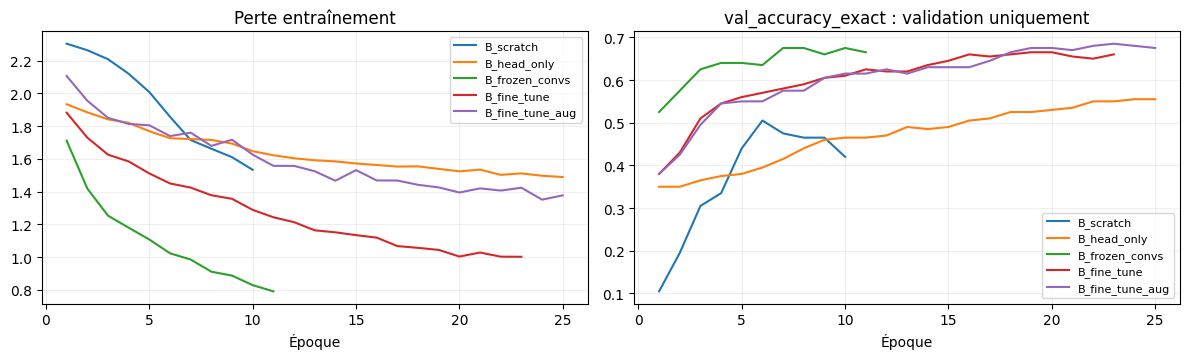

In [4]:
def freeze_strategy(m,strategy):
    for layer in m.layers:
        layer.trainable=(layer.name=='categorie') if strategy=='head_only' else layer.name not in ['conv1','conv2'] if strategy=='frozen_convs' else True
    return m
def smartphone_augmentation():
    return keras.Sequential([layers.RandomRotation(.05,fill_mode='constant',fill_value=.1,seed=42),
       layers.RandomTranslation(.08,.08,fill_mode='constant',fill_value=.1,seed=43),
       layers.RandomZoom(.10,fill_mode='constant',fill_value=.1,seed=44),layers.RandomContrast(.2,seed=45),
       SmartphoneBrightness(.12,seed=46)],name='smartphone_augmentation')
def adapted_cnn(strategy):
    base=source_cnn()
    if strategy!='scratch':base.set_weights(SOURCE.get_weights())
    base=freeze_strategy(base,strategy)
    if strategy=='fine_tune_aug':
        inp=keras.Input((28,28,1));m=keras.Model(inp,base(smartphone_augmentation()(inp)))
    else:m=base
    lr=1e-4 if strategy.startswith('fine_tune') else 1e-3
    m.compile(keras.optimizers.Adam(lr),'sparse_categorical_crossentropy');return m
THEORY=[]
for strategy,expected in [('head_only',1290),('frozen_convs',402826),('fine_tune',421642)]:
    m=freeze_strategy(source_cnn(),strategy);count=int(sum(np.prod(w.shape) for w in m.trainable_weights));assert count==expected
    THEORY.append({'strategy':strategy,'trainable_parameters':count})
write_json(OUT/'theory_checks.json',{'trainable_counts':THEORY,'category_loss_shares_lambda1_lambda5':[.35/.43,.35/.75],
    'gradient_warning':'Loss shares are not gradient norm shares.'});display(pd.DataFrame(THEORY))
STRATEGY_MODELS={};strategy_rows=[]
for strategy in ['scratch','head_only','frozen_convs','fine_tune','fine_tune_aug']:
    name='B_'+strategy
    m,info=fit_model(OUT,name,lambda s=strategy:adapted_cnn(s),IB['train'],YB['train'],IB['val'],YB['val'],epochs=CFG['target_epochs'],
        monitor='val_accuracy_exact',mode='max',evaluator=lambda p:{'val_accuracy_exact':classifier_metrics(YB['val'],p)['accuracy']},
        extra={'source_sha':source_info['model_sha'] if strategy!='scratch' else None})
    STRATEGY_MODELS[name]=m;strategy_rows.append(validation_row(OUT,name,info,classifier_metrics(YB['val'],predict(m,IB['val'])),strategy=strategy))
STRATEGY_VAL=write_table(OUT,'transfer_validation',strategy_rows)
SELECTED_STRATEGY=STRATEGY_VAL.sort_values(['accuracy','trainable_parameters'],ascending=[False,True]).iloc[0].model
learning_curves(OUT,list(STRATEGY_MODELS),'val_accuracy_exact','transfer_learning.png')

## 3. Modalités et modèle multitâche
 On copie les poids de l'encodeur source jusqu'à `representation`, on l'ajuste à
 faible LR, puis on concatène une projection Dense64 du BoW et une Dense128
 partagée. Têtes : dix catégories et un log-prix standardisé. L'augmentation
 décrite n'est appliquée qu'en entraînement.

 Contrôles à tâche unique et trois λ utilisent exactement cette même famille de
 tronc. Le nombre de paramètres/temps de chaque modèle est enregistré. Comparer
 multitâche aux contrôles sur validation, puis aux contrôles fixés dans le test
 final. Ne pas attribuer mécaniquement un gain à une tâche sans mesurer l'autre.

,model,source_model,macro_f1,accuracy
0,B_best_image_strategy,B_fine_tune_aug,0.658973,0.685
1,B_text_only,NaN,0.556343,0.555
2,B_image_text_single,NaN,0.519310,0.530


,model,macro_f1,accuracy,mape,mae_dh,rmse_dh,nonpositive_predictions,tradeoff,parameters,trainable_parameters,seconds,best_epoch,lambda_price,accuracy_gain_over_single,mape_gain_over_single
0,MT_lambda_0p1,0.524026,0.535,0.762912,192.524996,272.203169,0,0.344272,457355,457355,9.487313,23,0.1,0.005,-0.077324
1,MT_lambda_1p0,0.485653,0.510,0.673612,172.102654,249.835287,0,0.341597,457355,457355,9.182868,25,1.0,-0.020,0.011975
2,MT_lambda_5p0,0.333463,0.380,0.573066,160.742870,245.983663,0,0.236734,457355,457355,10.530432,25,5.0,-0.150,0.112521


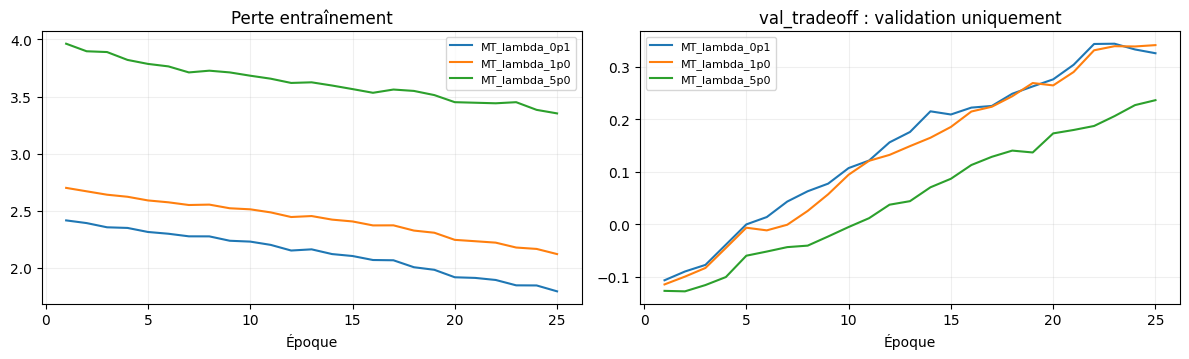

In [5]:
PRICE_MEAN=float(np.log(B['prix_train']).mean());PRICE_STD=float(np.log(B['prix_train']).std())
assert PRICE_STD>0
write_json(OUT/'log_price_scaler.json',{'mean':PRICE_MEAN,'std':PRICE_STD,'fitted_on':'B_train_only'})
BP={s:(np.log(B['prix_'+s])-PRICE_MEAN)/PRICE_STD for s in ['train','val']}
B_IN={s:{'image':IB[s],'mots':MB[s]} for s in ['train','val']}
def price_from_normalized(p):
    return np.exp(np.clip(np.asarray(p).reshape(-1)*PRICE_STD+PRICE_MEAN,np.log(1.),np.log(float(B['prix_train'].max())*10)))
def shared_model(task='joint',lam=1.):
    base=source_cnn();base.set_weights(SOURCE.get_weights())
    encoder=keras.Model(base.input,base.get_layer('representation').output,name='image_encoder')
    image=keras.Input((28,28,1),name='image');mots=keras.Input((169,),name='mots')
    xi=encoder(smartphone_augmentation()(image));xt=layers.Dense(64,activation='relu',name='text_representation')(mots)
    x=layers.Concatenate()([xi,xt]);x=layers.Dense(128,activation='relu',kernel_regularizer=keras.regularizers.l2(1e-4),name='shared')(x)
    x=layers.Dropout(.3)(x)
    cat=layers.Dense(10,activation='softmax',name='categorie')(x);price=layers.Dense(1,activation='linear',name='logprix')(x)
    outputs={'categorie':cat,'logprix':price} if task=='joint' else cat if task=='category' else price
    m=keras.Model({'image':image,'mots':mots},outputs)
    if task=='joint':m.compile(keras.optimizers.Adam(1e-4),loss={'categorie':'sparse_categorical_crossentropy','logprix':keras.losses.Huber(.5)},loss_weights={'categorie':1.,'logprix':lam})
    else:m.compile(keras.optimizers.Adam(1e-4),'sparse_categorical_crossentropy' if task=='category' else keras.losses.Huber(.5))
    return m
B_TEXT,btext_info=fit_model(OUT,'B_text_only',source_text,MB['train'],YB['train'],MB['val'],YB['val'],epochs=CFG['target_epochs'],
    monitor='val_accuracy_exact',mode='max',evaluator=lambda p:{'val_accuracy_exact':classifier_metrics(YB['val'],p)['accuracy']})
SINGLE_CAT,cat_info=fit_model(OUT,'B_single_category',lambda:shared_model('category'),B_IN['train'],YB['train'],B_IN['val'],YB['val'],epochs=CFG['target_epochs'],
    monitor='val_accuracy_exact',mode='max',evaluator=lambda p:{'val_accuracy_exact':classifier_metrics(YB['val'],p)['accuracy']},extra={'source_sha':source_info['model_sha']})
SINGLE_PRICE,price_info=fit_model(OUT,'B_single_price',lambda:shared_model('price'),B_IN['train'],BP['train'],B_IN['val'],BP['val'],epochs=CFG['target_epochs'],
    monitor='val_mape_dh',mode='min',evaluator=lambda p:{'val_mape_dh':price_metrics(B['prix_val'],price_from_normalized(p))['mape']},extra={'source_sha':source_info['model_sha']})
MODALITY_ROWS=[{'model':'B_best_image_strategy','source_model':SELECTED_STRATEGY,**classifier_metrics(YB['val'],predict(STRATEGY_MODELS[SELECTED_STRATEGY],IB['val']))},
     {'model':'B_text_only',**classifier_metrics(YB['val'],predict(B_TEXT,MB['val']))},
     {'model':'B_image_text_single',**classifier_metrics(YB['val'],predict(SINGLE_CAT,B_IN['val']))}]
MODALITY_VAL=write_table(OUT,'B_modality_validation',MODALITY_ROWS)
single_cat_metric=classifier_metrics(YB['val'],predict(SINGLE_CAT,B_IN['val']))
single_price_metric=price_metrics(B['prix_val'],price_from_normalized(predict(SINGLE_PRICE,B_IN['val'])))
joint_rows=[];JOINT_MODELS={}
def joint_evaluation(p):
    cm=classifier_metrics(YB['val'],p['categorie']);pm=price_metrics(B['prix_val'],price_from_normalized(p['logprix']))
    return {'val_accuracy_exact':cm['accuracy'],'val_mape_dh':pm['mape'],'val_tradeoff':cm['accuracy']-.25*pm['mape']}
for lam in CFG['lambdas']:
    name='MT_lambda_'+str(lam).replace('.','p')
    m,info=fit_model(OUT,name,lambda l=lam:shared_model('joint',l),B_IN['train'],{'categorie':YB['train'],'logprix':BP['train']},
        B_IN['val'],{'categorie':YB['val'],'logprix':BP['val']},epochs=CFG['target_epochs'],monitor='val_tradeoff',mode='max',
        evaluator=joint_evaluation,extra={'source_sha':source_info['model_sha'],'lambda':lam})
    p=predict(m,B_IN['val']);cm=classifier_metrics(YB['val'],p['categorie']);pm=price_metrics(B['prix_val'],price_from_normalized(p['logprix']))
    joint_rows.append(validation_row(OUT,name,info,{**cm,**pm,'tradeoff':cm['accuracy']-.25*pm['mape']},lambda_price=lam,
        accuracy_gain_over_single=cm['accuracy']-single_cat_metric['accuracy'],mape_gain_over_single=single_price_metric['mape']-pm['mape']))
    JOINT_MODELS[name]=m
MT_VAL=write_table(OUT,'multitask_validation',joint_rows)
SELECTED_MT=MT_VAL.sort_values(['tradeoff','parameters'],ascending=[False,True]).iloc[0].model
SELECTED_LAMBDA=float(MT_VAL.set_index('model').loc[SELECTED_MT,'lambda_price'])
write_json(OUT/'single_task_validation.json',{'category':single_cat_metric,'price':single_price_metric})
learning_curves(OUT,list(JOINT_MODELS),'val_tradeoff','multitask_learning.png')

### 3.1 Révision guidée par validation : nouvelles têtes et texte transféré

Le premier essai multitâche ajuste une tête aléatoire directement à LR=1e-4.
Ses courbes de validation montrent un apprentissage lent sur seulement quatre
mini-lots par époque. **Aucun test n'est encore ouvert.** Nous conservons ces
essais infructueux et ajoutons une stratégie à budget total inchangé :
1. transférer aussi la projection du modèle texte appris sur A ;
2. entraîner les nouvelles couches dix époques au maximum à LR=1e-3, encodeurs gelés ;
3. dégeler et recompiler à LR=1e-4 pour quinze époques au maximum.

Le budget B reste 25 époques maximum par candidat, comme l'essai direct. Les
contrôles à une tâche reçoivent le même échauffement et le même texte transféré.
Cette révision associe deux changements et **n'isole pas leur effet individuel**.
Elle est motivée uniquement par validation. λ et la stratégie finale restent
sélectionnés sur B val ; les essais directs restent dans le journal et le tableau.


Famille retenue avant test : MT_warm_lambda_1p0 | contrôles équitables : B_warm_single_category B_warm_single_price


,model,macro_f1,accuracy,mape,mae_dh,rmse_dh,nonpositive_predictions,tradeoff,parameters,trainable_parameters,seconds,best_epoch,lambda_price,accuracy_gain_over_single,mape_gain_over_single,training_scheme,warm_best_epoch
0,MT_lambda_0p1,0.524026,0.535,0.762912,192.524996,272.203169,0,0.344272,457355,457355,9.487313,23,0.1,0.005,-0.077324,direct_low_lr_random_text,NaN
1,MT_lambda_1p0,0.485653,0.510,0.673612,172.102654,249.835287,0,0.341597,457355,457355,9.182868,25,1.0,-0.020,0.011975,direct_low_lr_random_text,NaN
2,MT_lambda_5p0,0.333463,0.380,0.573066,160.742870,245.983663,0,0.236734,457355,457355,10.530432,25,5.0,-0.150,0.112521,direct_low_lr_random_text,NaN
3,MT_warm_lambda_0p1,0.809266,0.810,0.676293,168.392982,254.396765,0,0.640927,476427,476427,9.870484,11,0.1,0.035,-0.211286,warm_heads_plus_transferred_text,10.0
4,MT_warm_lambda_1p0,0.807814,0.810,0.473533,141.416477,225.998808,0,0.691617,476427,476427,11.700364,14,1.0,0.035,-0.008527,warm_heads_plus_transferred_text,10.0
5,MT_warm_lambda_5p0,0.713803,0.720,0.473455,144.242001,226.942083,0,0.601636,476427,476427,10.393094,15,5.0,-0.055,-0.008449,warm_heads_plus_transferred_text,10.0


,model,source_model,macro_f1,accuracy
0,B_best_image_strategy,B_fine_tune_aug,0.658973,0.685
1,B_text_only,NaN,0.556343,0.555
2,B_image_text_single,NaN,0.519310,0.530
3,B_image_text_warm_transferred_text,NaN,0.770746,0.775


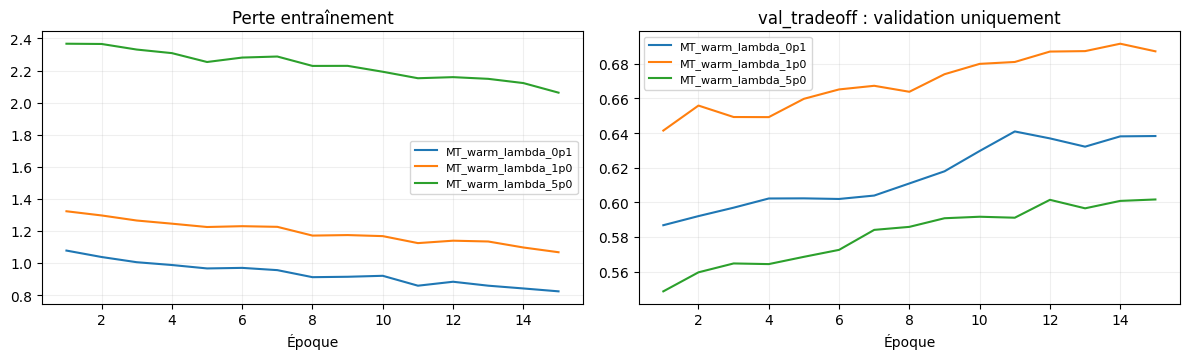

In [6]:
INITIAL_MT_VAL=MT_VAL.copy();INITIAL_MT_VAL['training_scheme']='direct_low_lr_random_text'
INITIAL_MT_VAL.to_csv(OUT/'multitask_initial_validation.csv',index=False)
initial_single_cat=SINGLE_CAT;initial_single_price=SINGLE_PRICE
def warm_shared_model(task='joint',lam=1.):
    base=source_cnn();base.set_weights(SOURCE.get_weights())
    image_encoder=keras.Model(base.input,base.get_layer('representation').output,name='image_encoder');image_encoder.trainable=False
    text_base=keras.models.clone_model(TEXT_SOURCE);text_base.set_weights(TEXT_SOURCE.get_weights())
    text_encoder=keras.Model(text_base.input,text_base.layers[1].output,name='text_encoder');text_encoder.trainable=False
    image=keras.Input((28,28,1),name='image');mots=keras.Input((169,),name='mots')
    xi=image_encoder(smartphone_augmentation()(image));xt=text_encoder(mots)
    x=layers.Concatenate()([xi,xt]);x=layers.Dense(128,activation='relu',kernel_regularizer=keras.regularizers.l2(1e-4),name='shared')(x)
    x=layers.Dropout(.3)(x);cat=layers.Dense(10,activation='softmax',name='categorie')(x);price=layers.Dense(1,activation='linear',name='logprix')(x)
    out={'categorie':cat,'logprix':price} if task=='joint' else cat if task=='category' else price
    m=keras.Model({'image':image,'mots':mots},out);compile_warm_model(m,task,lam,1e-3);return m
def compile_warm_model(m,task,lam,lr):
    if task=='joint':m.compile(keras.optimizers.Adam(lr),loss={'categorie':'sparse_categorical_crossentropy','logprix':keras.losses.Huber(.5)},loss_weights={'categorie':1.,'logprix':lam})
    else:m.compile(keras.optimizers.Adam(lr),'sparse_categorical_crossentropy' if task=='category' else keras.losses.Huber(.5))
def two_stage_fit(name,task,lam=1.):
    if task=='joint':
        yt={'categorie':YB['train'],'logprix':BP['train']};yv={'categorie':YB['val'],'logprix':BP['val']}
        metric='val_tradeoff';mode='max';evaluate=joint_evaluation
    elif task=='category':
        yt=YB['train'];yv=YB['val'];metric='val_accuracy_exact';mode='max'
        evaluate=lambda p:{'val_accuracy_exact':classifier_metrics(YB['val'],p)['accuracy']}
    else:
        yt=BP['train'];yv=BP['val'];metric='val_mape_dh';mode='min'
        evaluate=lambda p:{'val_mape_dh':price_metrics(B['prix_val'],price_from_normalized(p))['mape']}
    extra={'source_image_sha':source_info['model_sha'],'source_text_sha':text_source_info['model_sha'],'phase':'warm_frozen'}
    warm,winfo=fit_model(OUT,name+'_warmup',lambda:warm_shared_model(task,lam),B_IN['train'],yt,B_IN['val'],yv,epochs=10,
        monitor=metric,mode=mode,evaluator=evaluate,extra=extra)
    def unfreeze():
        m=keras.models.clone_model(warm);m.set_weights(warm.get_weights())
        m.get_layer('image_encoder').trainable=True;m.get_layer('text_encoder').trainable=True
        compile_warm_model(m,task,lam,1e-4);return m
    m,info=fit_model(OUT,name,unfreeze,B_IN['train'],yt,B_IN['val'],yv,epochs=15,monitor=metric,mode=mode,evaluator=evaluate,
        extra={'warm_sha':winfo['model_sha'],'phase':'unfrozen_low_lr'})
    return m,info,winfo
WARM_CAT,wcat_info,wcat_warm=two_stage_fit('B_warm_single_category','category')
WARM_PRICE,wprice_info,wprice_warm=two_stage_fit('B_warm_single_price','price')
warm_single_cat_metric=classifier_metrics(YB['val'],predict(WARM_CAT,B_IN['val']))
warm_single_price_metric=price_metrics(B['prix_val'],price_from_normalized(predict(WARM_PRICE,B_IN['val'])))
warm_rows=[]
for lam in CFG['lambdas']:
    name='MT_warm_lambda_'+str(lam).replace('.','p')
    m,info,winfo=two_stage_fit(name,'joint',lam)
    pred=predict(m,B_IN['val']);cm=classifier_metrics(YB['val'],pred['categorie']);pm=price_metrics(B['prix_val'],price_from_normalized(pred['logprix']))
    warm_rows.append(validation_row(OUT,name,info,{**cm,**pm,'tradeoff':cm['accuracy']-.25*pm['mape']},lambda_price=lam,
        training_scheme='warm_heads_plus_transferred_text',seconds=info['seconds']+winfo['seconds'],warm_best_epoch=winfo['best_epoch'],
        accuracy_gain_over_single=cm['accuracy']-warm_single_cat_metric['accuracy'],mape_gain_over_single=warm_single_price_metric['mape']-pm['mape']))
    JOINT_MODELS[name]=m
MT_VAL=write_table(OUT,'multitask_validation',[*INITIAL_MT_VAL.to_dict('records'),*warm_rows])
SELECTED_MT=MT_VAL.sort_values(['tradeoff','parameters'],ascending=[False,True]).iloc[0].model
SELECTED_LAMBDA=float(MT_VAL.set_index('model').loc[SELECTED_MT,'lambda_price'])
if SELECTED_MT.startswith('MT_warm'):
    SINGLE_CAT=WARM_CAT;SINGLE_PRICE=WARM_PRICE
    SINGLE_CAT_NAME='B_warm_single_category';SINGLE_PRICE_NAME='B_warm_single_price'
else:
    SINGLE_CAT=initial_single_cat;SINGLE_PRICE=initial_single_price
    SINGLE_CAT_NAME='B_single_category';SINGLE_PRICE_NAME='B_single_price'
controls={'family':SINGLE_CAT_NAME,'category':classifier_metrics(YB['val'],predict(SINGLE_CAT,B_IN['val'])),
          'price':price_metrics(B['prix_val'],price_from_normalized(predict(SINGLE_PRICE,B_IN['val'])))}
write_json(OUT/'single_task_validation.json',controls)
MODALITY_ROWS.append({'model':'B_image_text_warm_transferred_text',**warm_single_cat_metric})
MODALITY_VAL=write_table(OUT,'B_modality_validation',MODALITY_ROWS)
learning_curves(OUT,[name for name in JOINT_MODELS if name.startswith('MT_warm')],'val_tradeoff','multitask_warm_learning.png')
print('Famille retenue avant test :',SELECTED_MT,'| contrôles équitables :',SINGLE_CAT_NAME,SINGLE_PRICE_NAME)

In [7]:
selection={'multitask':SELECTED_MT,'lambda':SELECTED_LAMBDA,'selection_metric':'B val accuracy - .25*MAPE',
    'fixed_comparators':['CNN_A_source',SINGLE_CAT_NAME,SINGLE_PRICE_NAME],
    'models':[SELECTED_MT,'CNN_A_source',SINGLE_CAT_NAME,SINGLE_PRICE_NAME]}
def evaluate_final():
    at=load_catalogue(ROOT,'A',('test',));bt=load_catalogue(ROOT,'B',('test',))
    ax={'image':image_input(at,'test'),'mots':bow_input(BOW,at,'test')};bx={'image':image_input(bt,'test'),'mots':bow_input(BOW,bt,'test')}
    bp=predict(JOINT_MODELS[SELECTED_MT],bx);ap=predict(JOINT_MODELS[SELECTED_MT],ax)
    sb=predict(SOURCE,bx['image']);sa=predict(SOURCE,ax['image'])
    single_cat=predict(SINGLE_CAT,bx);single_price=price_from_normalized(predict(SINGLE_PRICE,bx))
    price=price_from_normalized(bp['logprix'])
    np.savez_compressed(OUT/'test_predictions.npz',B_category_true=bt['categorie_test'],B_price_true=bt['prix_test'],
        B_joint_probability=bp['categorie'],B_joint_price=price,B_source_probability=sb,B_single_probability=single_cat,B_single_price=single_price,
        A_category_true=at['categorie_test'],A_joint_probability=ap['categorie'],A_source_probability=sa)
    return {'B_multitask_category':classifier_metrics(bt['categorie_test'],bp['categorie']),
        'B_multitask_price':price_metrics(bt['prix_test'],price),'B_source_no_adaptation':classifier_metrics(bt['categorie_test'],sb),
        'B_single_category':classifier_metrics(bt['categorie_test'],single_cat),'B_single_price':price_metrics(bt['prix_test'],single_price),
        'A_source_category':classifier_metrics(at['categorie_test'],sa),'A_after_B_multitask_category':classifier_metrics(at['categorie_test'],ap['categorie'])}
TEST=test_once(OUT,selection,evaluate_final);display(pd.DataFrame(TEST).T)

,macro_f1,accuracy,mape,mae_dh,rmse_dh,nonpositive_predictions
B_multitask_category,0.799665,0.804000,NaN,NaN,NaN,NaN
B_multitask_price,NaN,NaN,0.509020,145.705311,225.025920,0.0
B_source_no_adaptation,0.293684,0.293500,NaN,NaN,NaN,NaN
B_single_category,0.783743,0.787000,NaN,NaN,NaN,NaN
B_single_price,NaN,NaN,0.494918,142.444053,221.604254,0.0
A_source_category,0.894549,0.894833,NaN,NaN,NaN,NaN
A_after_B_multitask_category,0.652549,0.690167,NaN,NaN,NaN,NaN


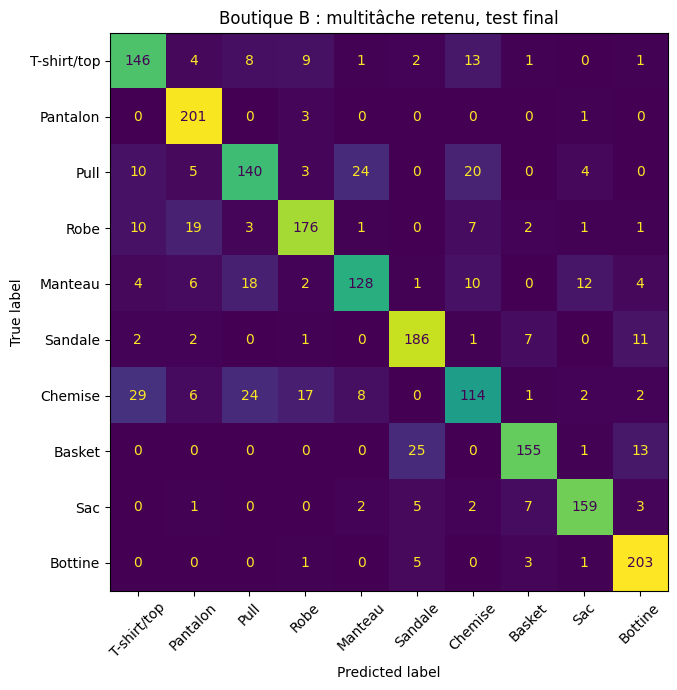

,category,f1,support,source_f1,adaptation_gain
0,T-shirt/top,0.756477,185,0.313901,0.442575
1,Pantalon,0.895323,205,0.727273,0.168050
2,Pull,0.701754,206,0.355987,0.345767
3,Robe,0.814815,220,0.078603,0.736212
4,Manteau,0.733524,185,0.241245,0.492279
5,Sandale,0.857143,210,0.146552,0.710591
6,Chemise,0.616216,203,0.150376,0.465840
7,Basket,0.837838,194,0.205357,0.632481
8,Sac,0.883333,179,0.227097,0.656237
9,Bottine,0.900222,213,0.490446,0.409776


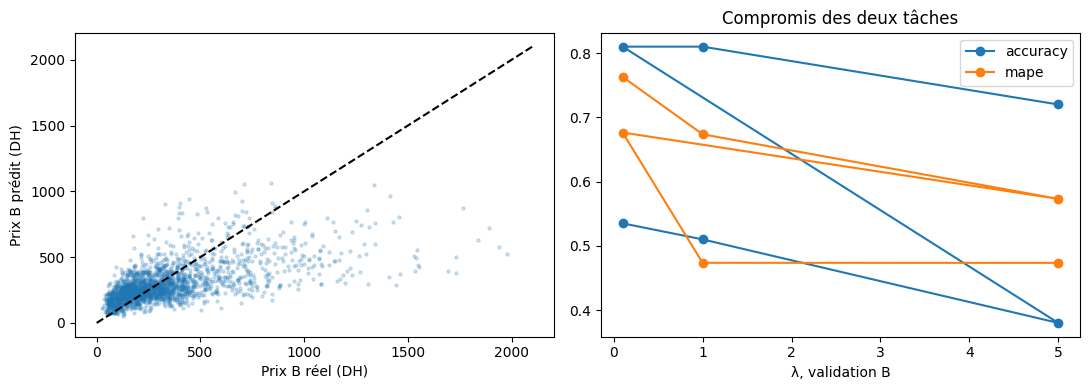

In [8]:
z=np.load(OUT/'test_predictions.npz');show_confusion(z['B_category_true'],z['B_joint_probability'],OUT,title='Boutique B : multitâche retenu, test final')
b=per_class(z['B_category_true'],z['B_joint_probability']);s=per_class(z['B_category_true'],z['B_source_probability'])
b['source_f1']=s.f1;b['adaptation_gain']=b.f1-b.source_f1;display(b);b.to_csv(OUT/'test_B_per_class.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(z['B_price_true'],z['B_joint_price'],s=5,alpha=.2);axes[0].plot([0,2100],[0,2100],'k--');axes[0].set(xlabel='Prix B réel (DH)',ylabel='Prix B prédit (DH)')
MT_VAL.set_index('lambda_price')[['accuracy','mape']].plot(ax=axes[1],marker='o');axes[1].set_xlabel('λ, validation B');axes[1].set_title('Compromis des deux tâches')
fig.tight_layout();fig.savefig(OUT/'multitask_tradeoff_and_price.png',dpi=150);plt.show();plt.close(fig)
write_json(OUT/'test_confidence_intervals.json',{'B_accuracy_95pct':relative_ci(z['B_category_true'],z['B_joint_probability'],lambda y,p:classifier_metrics(y,p)['accuracy']),'resamples':300})

### Comparaison des deux tâches et préservation du catalogue A
Dans le test livré, le multitâche ajoute **1,7 point** d'accuracy B face au
contrôle catégorie réchauffé, mais augmente la MAPE prix de **1,41 point**.
Il améliore donc la catégorie et dégrade légèrement le prix dans ce protocole.
La F1 A chute de **0,8945 à 0,6525** après adaptation : conserver le modèle A
séparément est nécessaire. Les deux changements de la révision (transfert du
texte et échauffement) ont été combinés ; leur effet individuel n'est pas isolé.
Les cibles B et prix ne sont pas atteintes. Aucun ajustement n'est effectué
après cette évaluation finale.


In [9]:
val_strategy=STRATEGY_VAL.set_index('model').loc[SELECTED_STRATEGY]
cat_gain=TEST['B_multitask_category']['accuracy']-TEST['B_single_category']['accuracy']
price_gain=TEST['B_single_price']['mape']-TEST['B_multitask_price']['mape']
decision=f"""# Décisions Jalon 3
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Décalage :** les fonds/contrastes changent dans les images B ; exemples par classe et mesures de bord sont fournis. La baisse source A→B et la robustesse relative du texte se mesurent sur `source_domain_validation.csv`. Ce sont des transformations pédagogiques, sans preuve sur une boutique réelle.

**Adaptation mensuelle :** stratégie image préférée par validation={SELECTED_STRATEGY}, accuracy B val={val_strategy.accuracy:.4f}. Utiliser d'abord une tête gelée comme référence peu coûteuse, puis appliquer la stratégie validée avec faible LR et augmentation si elle améliore la validation. Réserver une validation de chaque nouvelle boutique avant remplacement. Ne pas décider en observant le test ni supposer qu'une stratégie gagne sur tous les domaines.

**Multitâche :** essais directs conservés, puis échauffement de têtes/texte transféré à budget B 10+15=25 époques maximum, révision motivée seulement par validation. Retenu {SELECTED_MT}, λ={SELECTED_LAMBDA}, choisi par accuracy−0,25×MAPE val. Test B accuracy={TEST['B_multitask_category']['accuracy']:.4f} (cible 0,82, écart={TEST['B_multitask_category']['accuracy']-.82:+.4f}), MAPE={TEST['B_multitask_price']['mape']:.4f} (cible 0,32, écart={TEST['B_multitask_price']['mape']-.32:+.4f}). Face aux contrôles à une tâche, gain catégorie={cat_gain:+.4f}, réduction MAPE={price_gain:+.4f}. Un gain positif démontre une amélioration dans ce protocole seulement ; un gain négatif signale un transfert négatif pour la tâche concernée.

Source sans adaptation sur B : accuracy={TEST['B_source_no_adaptation']['accuracy']:.4f}. Sur A, F1 source={TEST['A_source_category']['macro_f1']:.4f}, après ajustement B={TEST['A_after_B_multitask_category']['macro_f1']:.4f}. Cette mesure rend visible un éventuel oubli du catalogue A au lieu de supposer une conservation automatique.

**Théorie :** parts de perte catégorie 81,40% (λ1) et 46,67% (λ5), distinctes des normes de gradients. Paramètres entraînables source : sortie seule 1 290, conv gelées 402 826, complet 421 642. Le λ dépend de l'échelle du prix standardisé sur train B.

**Limites et décision :** seulement 200 exemples val B (une réussite change accuracy de 0,5 point), une graine, textes/prix simulés, risque d'oubli A. Garder le modèle A versionné et prévoir retour arrière/recours. Le multitâche ne doit pas être vendu comme bénéfique aux deux tâches si les comparaisons ci-dessus indiquent l'inverse.
"""
final_decision(OUT,decision)

Journal : 77 entrées. Modèles, décisions et résultats conservés dans /workspace/scratch/5ba8c7023440/uc2_submission_work/submission/GroupeXX_UC2/artifacts/jalon3


# Décisions Jalon 3
Groupe XX, UC2. Agrigah Aya, AARAB Mustapha, Toubani Badr Eddine.

**Décalage :** les fonds/contrastes changent dans les images B ; exemples par classe et mesures de bord sont fournis. La baisse source A→B et la robustesse relative du texte se mesurent sur `source_domain_validation.csv`. Ce sont des transformations pédagogiques, sans preuve sur une boutique réelle.

**Adaptation mensuelle :** stratégie image préférée par validation=B_fine_tune_aug, accuracy B val=0.6850. Utiliser d'abord une tête gelée comme référence peu coûteuse, puis appliquer la stratégie validée avec faible LR et augmentation si elle améliore la validation. Réserver une validation de chaque nouvelle boutique avant remplacement. Ne pas décider en observant le test ni supposer qu'une stratégie gagne sur tous les domaines.

**Multitâche :** essais directs conservés, puis échauffement de têtes/texte transféré à budget B 10+15=25 époques maximum, révision motivée seulement par validation. Retenu MT_warm_lambda_1p0, λ=1.0, choisi par accuracy−0,25×MAPE val. Test B accuracy=0.8040 (cible 0,82, écart=-0.0160), MAPE=0.5090 (cible 0,32, écart=+0.1890). Face aux contrôles à une tâche, gain catégorie=+0.0170, réduction MAPE=-0.0141. Un gain positif démontre une amélioration dans ce protocole seulement ; un gain négatif signale un transfert négatif pour la tâche concernée.

Source sans adaptation sur B : accuracy=0.2935. Sur A, F1 source=0.8945, après ajustement B=0.6525. Cette mesure rend visible un éventuel oubli du catalogue A au lieu de supposer une conservation automatique.

**Théorie :** parts de perte catégorie 81,40% (λ1) et 46,67% (λ5), distinctes des normes de gradients. Paramètres entraînables source : sortie seule 1 290, conv gelées 402 826, complet 421 642. Le λ dépend de l'échelle du prix standardisé sur train B.

**Limites et décision :** seulement 200 exemples val B (une réussite change accuracy de 0,5 point), une graine, textes/prix simulés, risque d'oubli A. Garder le modèle A versionné et prévoir retour arrière/recours. Le multitâche ne doit pas être vendu comme bénéfique aux deux tâches si les comparaisons ci-dessus indiquent l'inverse.


## Sources et limites de reproductibilité
 - Fiche UC2 du jalon, `Consignes.pdf` et code de départ fournis par l'enseignant
   (copies dans `sources/enseignant/`). Les NPZ incluent les partitions originales.
 - [Fashion-MNIST, Zalando Research](https://github.com/zalandoresearch/fashion-mnist).
 - [TensorFlow/Keras](https://www.tensorflow.org/guide/keras),
   [transfert et ajustement fin](https://keras.io/guides/transfer_learning/),
   [GRU](https://keras.io/api/layers/recurrent_layers/gru/),
   [masquage](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding).

 Une seule graine ne démontre pas la stabilité sur plusieurs initialisations.
 Le déterminisme dépend aussi des versions et du matériel. Les modèles, leurs
 empreintes, les versions et les prédictions finalisées sont inclus dans la remise.
 Les cibles sont celles du système final du cours ; une cible non atteinte est
 signalée, et ne justifie jamais un réglage sur le test.